# Customer Retention Intelligence — Next-Best-Action (Phase 9)

## Objective

Turn the frozen Phase 7 Logistic Regression's churn probability, plus
Phase 8's SHAP explanations, into a practical, auditable retention
recommendation:

```
customer features -> churn probability -> SHAP drivers -> risk segment
    -> recommended retention action (+ priority)
```

**This notebook does not retrain, retune, or modify the Phase 7 model or
the Phase 8 SHAP implementation.** It loads the frozen
`models/tuned_logistic_regression.joblib` pipeline, reuses
`src/models/explainability.py` unmodified for SHAP, and adds a new,
independent business-rule layer (`src/recommendations/`) on top.

**Critical framing, stated once here and repeated at the end:**

> The recommendation system maps model-observed customer signals to
> predefined business actions. It does not establish that taking an
> action will prevent churn. Measuring causal treatment effectiveness
> would require an appropriate experiment or causal inference framework.

**On using the full dataset (not just validation):** batch scoring below
runs over the *entire* Phase 4 feature dataset (train + validation + test
snapshots combined). This is an inference/business-reporting step, not a
model-design step -- nothing here trains, tunes, or measures the model's
*performance* using test-split labels. The `churn_next_30_days` label is
never read by the recommendation logic itself; it is only glanced at
descriptively, later, purely to sanity-check that the rule outputs look
reasonable, never to pick a threshold or an action rule.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

from src.models import baseline as bl
from src.models.explainability import load_tuned_pipeline
from src.recommendations import next_best_action as nba
from src.recommendations import rules

PROJECT_ROOT

PosixPath('/Users/dhananjaymandal/customer-retention-intelligence')

## 1. Load the Frozen Phase 7 Model and the Phase 9 Config

`load_tuned_pipeline` (from Phase 8, reused unmodified) refuses to load
anything that isn't exactly the Phase 7 selection (`C=0.01`,
`class_weight="balanced"`).

In [2]:
pipeline = load_tuned_pipeline()
config = nba.load_config()

print(pipeline.named_steps["model"])
print()
for section in ("risk_thresholds", "priority_thresholds", "signal_thresholds", "actions"):
    print(f"{section}:")
    print(f"  {config[section]}")

LogisticRegression(C=0.01, class_weight='balanced', max_iter=1000,
                   random_state=42)

risk_thresholds:
  {'low': 0.2, 'medium': 0.5, 'high': 0.8}
priority_thresholds:
  {'medium': 0.35, 'high': 0.65, 'urgent': 0.85, 'multi_signal_bump': True}
signal_thresholds:
  {'low_engagement': {'active_days_90d_max': 10, 'avg_active_minutes_90d_max': 14.0}, 'reduced_usage': {'active_minutes_pct_change_30d_max': -30.0, 'login_count_pct_change_30d_max': -30.0, 'feature_usage_count_pct_change_30d_max': -30.0}, 'support_problems': {'pending_ticket_count_90d_min': 1, 'high_critical_ticket_count_90d_min': 1, 'avg_satisfaction_90d_max': 2.5}, 'payment_problems': {'txn_failed_count_90d_min': 2, 'txn_failed_rate_90d_min': 0.2, 'days_since_last_successful_transaction_min': 60}}
actions:
  {'priority_retention_outreach': 'Priority retention outreach', 'billing_payment_assistance': 'Billing / payment assistance', 'customer_support_follow_up': 'Customer-support follow-up', 're_engagement_camp

## 2. Data-Driven Basis for the Business Thresholds

`configs/recommendation_config.yaml` documents every threshold as a
**business decision**, not a statistically optimized cutoff. The
percentiles below are exactly what motivated each choice (see the
comments in the config file itself for the full reasoning).

In [3]:
features = bl.load_feature_dataset()
print(f"Full feature dataset: {features.shape}")

percentile_columns = [
    "active_days_90d", "avg_active_minutes_90d",
    "active_minutes_pct_change_30d", "login_count_pct_change_30d", "feature_usage_count_pct_change_30d",
    "pending_ticket_count_90d", "high_critical_ticket_count_90d", "avg_satisfaction_90d",
    "txn_failed_count_90d", "txn_failed_rate_90d", "days_since_last_successful_transaction",
]
features[percentile_columns].describe(percentiles=[.1, .25, .5, .75, .9]).T

Full feature dataset: (136701, 134)


,count,mean,std,min,10%,25%,50%,75%,90%,max
active_days_90d,136701.0,16.542505,9.357983,0.0,8.000000,10.000000,14.000000,20.000000,28.000000,76.000000
avg_active_minutes_90d,136479.0,33.459321,26.286519,0.0,7.393800,13.804187,25.610833,45.890800,73.180907,174.051818
active_minutes_pct_change_30d,128948.0,36.552096,677.280175,-100.0,-51.345285,-28.744854,-0.052209,39.293853,102.176447,94604.000000
login_count_pct_change_30d,127351.0,9.723483,63.711047,-100.0,-41.666667,-20.454545,0.000000,24.444444,65.079365,2400.000000
feature_usage_count_pct_change_30d,127305.0,19.121828,99.211316,-100.0,-52.500000,-28.571429,0.000000,35.849057,100.000000,3500.000000
pending_ticket_count_90d,136701.0,0.169099,0.465544,0.0,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000
high_critical_ticket_count_90d,136701.0,0.165266,0.460926,0.0,0.000000,0.000000,0.000000,0.000000,1.000000,7.000000
avg_satisfaction_90d,63815.0,3.379105,0.841848,1.0,2.000000,3.000000,3.400000,4.000000,4.333333,5.000000
txn_failed_count_90d,136701.0,0.198353,0.457936,0.0,0.000000,0.000000,0.000000,0.000000,1.000000,5.000000
txn_failed_rate_90d,136701.0,0.046748,0.128076,0.0,0.000000,0.000000,0.000000,0.000000,0.200000,1.000000


## 3. Reproduce the Chronological Split (for the SHAP Background Only)

The SHAP background must come from TRAIN only, exactly as in Phase 8 --
reproducing the split here is solely to get that TRAIN slice; it has
nothing to do with model selection.

In [4]:
splits = bl.split_by_snapshot_date(features)
numeric_columns, categorical_columns = bl.get_feature_columns(features)
feature_columns = numeric_columns + categorical_columns

X_train = splits["train"][feature_columns]
print(f"TRAIN rows used for SHAP background: {len(X_train)}")

TRAIN rows used for SHAP background: 85419


## 4. Build the SHAP Context (Phase 8 Reused, Unmodified)

`build_shap_context` calls straight into `src/models/explainability.py`'s
`build_feature_metadata`, `build_background`, and `build_explainer` --
none of that code is duplicated or changed here.

In [5]:
shap_context = nba.build_shap_context(pipeline, X_train, categorical_columns)
print(f"SHAP background shape: {shap_context['explainer'].masker.data.shape if hasattr(shap_context['explainer'], 'masker') else 'n/a'}")
print(f"Transformed feature count: {len(shap_context['display_names'])}")

SHAP background shape: (100, 142)
Transformed feature count: 142


## 5. Score Every Customer/Snapshot and Generate Recommendations

`generate_batch_recommendations` scores with the frozen pipeline
(`predict_risk`), computes each row's top-3 positive SHAP drivers
(`compute_top_positive_shap_drivers`), evaluates the four business-rule
signal categories (`src/recommendations/rules.py`), and applies the
rule table in `determine_action` -- all in one pass over the full
dataset.

In [6]:
import time

start = time.perf_counter()
recommendations = nba.generate_batch_recommendations(
    pipeline, features, feature_columns, config, shap_context=shap_context, top_k_shap=3
)
elapsed = time.perf_counter() - start

print(f"Generated {len(recommendations)} recommendations in {elapsed:.1f}s")
recommendations.head(5)

Generated 136701 recommendations in 5.9s


,customer_id,snapshot_date,churn_probability,risk_level,primary_action,action_key,action_reason,supporting_features,priority
0,C000001,2025-05-31,0.247817,medium,No intervention,no_intervention,Predicted churn risk is medium (probability=0....,"[model_signal:avg_pages_viewed_90d, model_sign...",low
1,C000001,2025-06-30,0.331325,medium,No intervention,no_intervention,Predicted churn risk is medium (probability=0....,"[model_signal:avg_pages_viewed_90d, model_sign...",low
2,C000001,2025-07-31,0.410223,medium,No intervention,no_intervention,Predicted churn risk is medium (probability=0....,"[model_signal:active_days_90d, model_signal:av...",medium
3,C000001,2025-08-31,0.496815,medium,No intervention,no_intervention,Predicted churn risk is medium (probability=0....,"[model_signal:active_days_90d, model_signal:av...",medium
4,C000001,2025-09-30,0.475294,medium,No intervention,no_intervention,Predicted churn risk is medium (probability=0....,"[model_signal:active_days_90d, model_signal:av...",medium


## 6. Risk Segmentation Sanity Check

**Important caveat:** the Phase 7 model uses `class_weight="balanced"`,
which shifts predicted probabilities upward across the board relative to
the true ~1.2% churn rate (confirmed below). That is exactly why "medium"
and "high" dominate the risk-level distribution rather than "low" -- it
reflects the model's balanced-training calibration, not a claim that most
customers are actually near-certain to churn.

In [7]:
actual_churn_rate = features["churn_next_30_days"].mean()
print(f"Actual churn rate in the full dataset (descriptive only, not used by the rules): {actual_churn_rate:.4f}")
print(f"Mean predicted churn probability: {recommendations['churn_probability'].mean():.4f}")

Actual churn rate in the full dataset (descriptive only, not used by the rules): 0.0122
Mean predicted churn probability: 0.5010


## 7. Distribution of Risk Levels

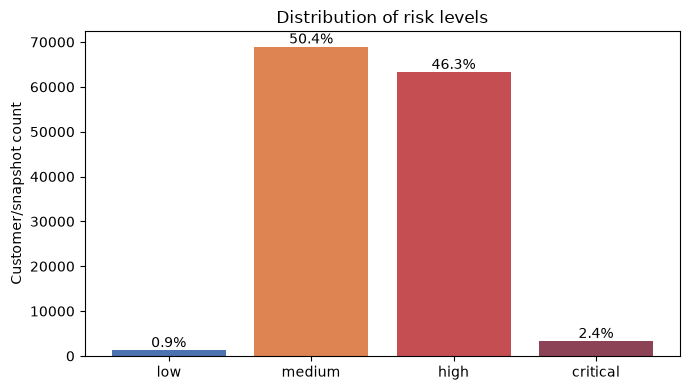

,count,percentage
risk_level,,
low,1234,0.90
medium,68935,50.43
high,63255,46.27
critical,3277,2.40


In [8]:
risk_level_counts = recommendations["risk_level"].value_counts().reindex(nba.RISK_LEVELS).fillna(0).astype(int)
risk_level_pct = (risk_level_counts / len(recommendations) * 100).round(2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(risk_level_counts.index, risk_level_counts.values, color=["#4C72B0", "#DD8452", "#C44E52", "#8C4356"])
ax.set_ylabel("Customer/snapshot count")
ax.set_title("Distribution of risk levels")
for i, (count, pct) in enumerate(zip(risk_level_counts.values, risk_level_pct.values)):
    ax.text(i, count, f"{pct:.1f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()

pd.DataFrame({"count": risk_level_counts, "percentage": risk_level_pct})

## 8. Distribution of Recommended Actions

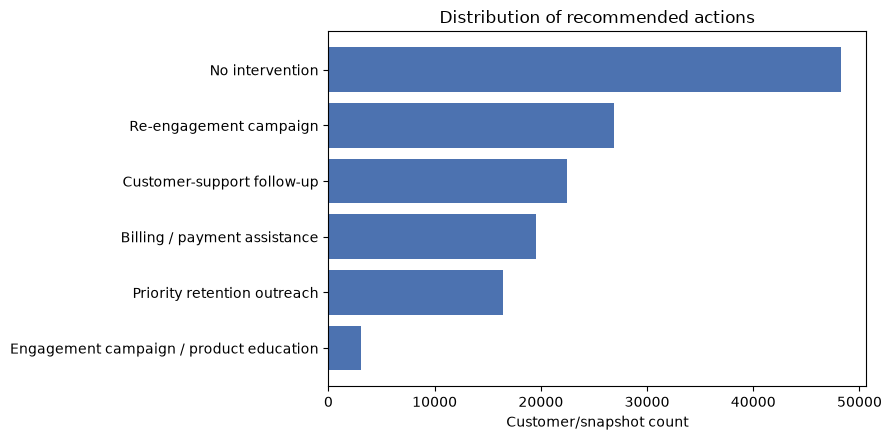

,count,percentage
primary_action,,
No intervention,48219,35.27
Re-engagement campaign,26888,19.67
Customer-support follow-up,22487,16.45
Billing / payment assistance,19549,14.30
Priority retention outreach,16449,12.03
Engagement campaign / product education,3109,2.27


In [9]:
action_counts = recommendations["primary_action"].value_counts()
action_pct = (action_counts / len(recommendations) * 100).round(2)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(action_counts.index[::-1], action_counts.values[::-1], color="#4C72B0")
ax.set_xlabel("Customer/snapshot count")
ax.set_title("Distribution of recommended actions")
plt.tight_layout()
plt.show()

pd.DataFrame({"count": action_counts, "percentage": action_pct})

## 9. Distribution of Intervention Priorities

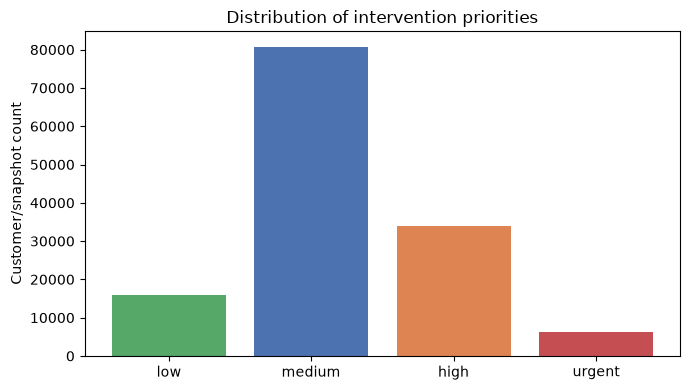

,count,percentage
priority,,
low,15808,11.56
medium,80750,59.07
high,33986,24.86
urgent,6157,4.50


In [10]:
priority_counts = recommendations["priority"].value_counts().reindex(nba.PRIORITY_LEVELS).fillna(0).astype(int)
priority_pct = (priority_counts / len(recommendations) * 100).round(2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(priority_counts.index, priority_counts.values, color=["#55A868", "#4C72B0", "#DD8452", "#C44E52"])
ax.set_ylabel("Customer/snapshot count")
ax.set_title("Distribution of intervention priorities")
plt.tight_layout()
plt.show()

pd.DataFrame({"count": priority_counts, "percentage": priority_pct})

## 10. Relationship Between Churn Probability and Priority

Priority is derived from probability (via `priority_thresholds`) plus a
one-level bump when 2+ signal categories are triggered simultaneously --
so probability should clearly separate by priority band, with some
overlap where the multi-signal bump moved a customer up a level.

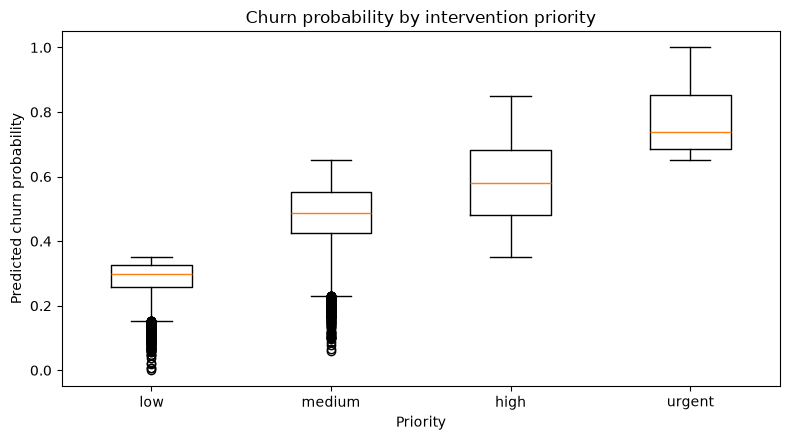

,mean,min,max,count
priority,,,,
low,0.286113,0.001121,0.349995,15808
medium,0.488113,0.059265,0.649991,80750
high,0.583967,0.350094,0.849993,33986
urgent,0.764248,0.650046,1.000000,6157


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
data_by_priority = [recommendations.loc[recommendations["priority"] == p, "churn_probability"] for p in nba.PRIORITY_LEVELS]
ax.boxplot(data_by_priority, tick_labels=nba.PRIORITY_LEVELS)
ax.set_ylabel("Predicted churn probability")
ax.set_xlabel("Priority")
ax.set_title("Churn probability by intervention priority")
plt.tight_layout()
plt.show()

recommendations.groupby("priority")["churn_probability"].agg(["mean", "min", "max", "count"]).reindex(nba.PRIORITY_LEVELS)

## 11. Example Recommendations

One example per action category, formatted the way this would be
surfaced to a retention team.

In [12]:
def print_recommendation(row: pd.Series) -> None:
    print(f"Customer: {row['customer_id']}  (snapshot {pd.Timestamp(row['snapshot_date']).date()})")
    print(f"Churn probability: {row['churn_probability']:.2f}")
    print(f"Risk level: {row['risk_level']}")
    print(f"Priority: {row['priority']}")
    print()
    print(f"Recommended action:\n{row['primary_action']}")
    print()
    print(f"Reason:\n{row['action_reason']}")
    print()
    supporting = row["supporting_features"]
    if supporting:
        print("Supporting signals:")
        for feature in supporting:
            print(f"  - {feature}")
    else:
        print("Supporting signals: (none -- no business rule triggered)")
    print("-" * 70)


example_ids = (
    recommendations.sort_values("churn_probability", ascending=False)
    .groupby("action_key")
    .head(1)
    .sort_values("action_key")
)
for _, row in example_ids.iterrows():
    print_recommendation(row)

Customer: C007963  (snapshot 2026-05-31)
Churn probability: 0.97
Risk level: critical
Priority: urgent

Recommended action:
Billing / payment assistance

Reason:
Elevated payment/transaction problems detected in the last 90 days.

Supporting signals:
  - txn_failed_count_90d=2 (>= 2)
  - txn_failed_rate_90d=0.2 (>= 0.2)
  - model_signal:active_days_90d
  - model_signal:txn_failed_count_180d
  - model_signal:txn_purchase_count_180d
----------------------------------------------------------------------
Customer: C009572  (snapshot 2026-04-30)
Churn probability: 0.99
Risk level: critical
Priority: urgent

Recommended action:
Customer-support follow-up

Reason:
Unresolved, high-severity, or low-satisfaction support activity detected in the last 90 days.

Supporting signals:
  - pending_ticket_count_90d=3 (>= 1)
  - high_critical_ticket_count_90d=4 (>= 1)
  - model_signal:active_days_90d
  - model_signal:txn_amount_sum_90d
  - model_signal:txn_upgrade_count_90d
-----------------------------

## 12. Examples Where No Intervention Is Recommended

Two flavors: genuinely low risk, and non-trivial risk with no configured
signal triggered (the "insufficient evidence" case).

In [13]:
no_intervention = recommendations[recommendations["action_key"] == "no_intervention"]

low_risk_example = no_intervention[no_intervention["risk_level"] == "low"].sort_values("churn_probability").iloc[0]
print("=== Low-risk, no intervention ===")
print_recommendation(low_risk_example)

insufficient_evidence = no_intervention[no_intervention["risk_level"] != "low"]
if len(insufficient_evidence) > 0:
    example = insufficient_evidence.sort_values("churn_probability", ascending=False).iloc[0]
    print("\n=== Non-trivial risk, but no signal triggered ===")
    print_recommendation(example)
else:
    print("\nNo 'non-trivial risk, no signal triggered' examples in this dataset.")

=== Low-risk, no intervention ===
Customer: C002881  (snapshot 2025-02-28)
Churn probability: 0.01
Risk level: low
Priority: low

Recommended action:
No intervention

Reason:
Predicted churn risk is low (probability=0.01).

Supporting signals:
  - model_signal:session_minutes_pct_change_30d
  - model_signal:avg_active_minutes_previous30d
  - model_signal:avg_pages_viewed_90d
----------------------------------------------------------------------

=== Non-trivial risk, but no signal triggered ===
Customer: C009512  (snapshot 2025-08-31)
Churn probability: 1.00
Risk level: critical
Priority: urgent

Recommended action:
No intervention

Reason:
Predicted churn risk is critical (probability=1.00), but no configured business signal (engagement, usage trend, support, or payment) met its threshold -- insufficient evidence for a targeted intervention.

Supporting signals:
  - model_signal:session_minutes_pct_change_30d
  - model_signal:avg_pages_viewed_90d
  - model_signal:avg_active_minutes_pr

## 13. Save Outputs

- `reports/customer_recommendations.csv` -- every customer/snapshot's full recommendation, auditable via `supporting_features`.
- `reports/recommendation_summary.csv` -- risk level x action, with customer counts and percentages.

In [14]:
recommendations_path = nba.save_recommendations(recommendations)
print(f"Saved {len(recommendations)} recommendations -> {recommendations_path}")

summary = nba.build_recommendation_summary(recommendations)
summary_path = nba.save_recommendation_summary(summary)
print(f"Saved recommendation summary -> {summary_path}")
summary

Saved 136701 recommendations -> /Users/dhananjaymandal/customer-retention-intelligence/reports/customer_recommendations.csv
Saved recommendation summary -> /Users/dhananjaymandal/customer-retention-intelligence/reports/recommendation_summary.csv


,risk_level,primary_action,customer_count,percentage_of_customers
0,low,No intervention,681,0.498
1,low,Billing / payment assistance,236,0.173
2,low,Customer-support follow-up,154,0.113
3,low,Re-engagement campaign,138,0.101
4,low,Engagement campaign / product education,25,0.018
5,medium,No intervention,27347,20.005
6,medium,Re-engagement campaign,15262,11.165
7,medium,Billing / payment assistance,13425,9.821
8,medium,Customer-support follow-up,10825,7.919
9,medium,Engagement campaign / product education,2076,1.519


## 14. Decision-Support Disclaimer

> The recommendation system maps model-observed customer signals to
> predefined business actions. It does not establish that taking an
> action will prevent churn. Measuring causal treatment effectiveness
> would require an appropriate experiment or causal inference framework.

This is a **decision-support layer**: it prioritizes and explains where a
human/business team might look first, using observed associations between
features and predicted risk (Phase 7 + Phase 8). It is not a causal
treatment-effect model, and no action label here should be read as "this
action reduces churn" -- only as "this is the predefined action this
project maps this combination of signals to."

**Other limitations:**
- Business thresholds (`configs/recommendation_config.yaml`) are
  judgment calls grounded in this dataset's percentiles, not optimized
  against any real business outcome (e.g. retention lift, cost per
  outreach). They should be revisited with real intervention data.
- Risk-level proportions are skewed upward by the Phase 7 model's
  `class_weight="balanced"` training choice (Section 6) -- they should
  not be read as "this fraction of customers will churn."
- Rules only see the features listed in
  `src/recommendations/rules.REQUIRED_SIGNAL_FEATURES`; a customer with
  a real problem outside those specific columns (or with missing data on
  all of them) can still receive `no_intervention`.
- `model_signals` (SHAP-derived entries in `supporting_features`, prefixed
  `model_signal:`) reflect the *linear* Logistic Regression's own
  explanation for that row, inheriting every caveat from Phase 8
  (association, not causation; specific to this validation-era model).

In [15]:
print("reports/customer_recommendations.csv exists:", (PROJECT_ROOT / "reports" / "customer_recommendations.csv").exists())
print("reports/recommendation_summary.csv exists:", (PROJECT_ROOT / "reports" / "recommendation_summary.csv").exists())
print(f"\nTotal recommendations: {len(recommendations)}")
print(f"Unique customers: {recommendations['customer_id'].nunique()}")

reports/customer_recommendations.csv exists: True
reports/recommendation_summary.csv exists: True

Total recommendations: 136701
Unique customers: 9746
